# Process Mining appliqué à l'audit Purchase-to-Pay (P2P)
**Franck Nankeng** · Projet portfolio · Python, PM4Py · *données simulées*

> *English summary — Process mining on a simulated Purchase-to-Pay event log (2,000 orders, 18,618 events): process discovery, alignment-based conformance checking, five business-rule tests, bottleneck costing and a four-finding audit memo.*

Ce projet reproduit une mission type d'une équipe *IS Audit & Analytics* : reconstituer le processus achats réellement exécuté à partir des traces du SI, le confronter au processus attendu, et en tirer des constats d'audit chiffrés.

**Chaîne de valeur P2P attendue** (9 étapes, contrôle clé = rapprochement 3 voies) :

`Demande d'achat → Approbation DA → Création commande → Approbation commande → Réception marchandise → Réception facture → Rapprochement 3 voies → Validation paiement → Paiement`

**Plan**
1. Génération d'un event log synthétique (2 000 cas) avec anomalies injectées
2. Découverte du processus (inductive miner, DFG, variantes)
3. Conformance checking vs modèle attendu (alignments + règles métier)
4. Analyse des délais et chiffrage du goulot
5. Note de synthèse d'audit

## 0. Installation et imports

PM4Py nécessite le binaire Graphviz pour l'export des visuels (`apt-get install graphviz`).

⚠️ *Licence : PM4Py community est en AGPL v3 — un usage commercial interne en cabinet impose soit l'open-sourcing, soit une licence commerciale. À anticiper avant tout usage en cabinet.*

In [1]:
# !pip install pm4py pandas matplotlib
# !apt-get install -y graphviz
import warnings, numpy as np, pandas as pd, pm4py, matplotlib.pyplot as plt
from datetime import datetime, timedelta
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
print("pm4py", pm4py.__version__)

pm4py 2.7.23.8


## 1. Génération de l'event log P2P synthétique

Un event log = **3 colonnes minimales** : identifiant de cas, activité, horodatage. On y ajoute les attributs d'audit : `user` (pour la séparation des tâches), `montant` (pour chiffrer l'exposition), `fournisseur`.

**Les 4 familles d'anomalies injectées :**

| Anomalie | Mécanique | Risque d'audit |
|---|---|---|
| Paiement avant validation | `Paiement` placé avant `Rapprochement 3 voies` et `Validation paiement` | Contournement du contrôle clé — paiement non justifié, sur-facturation non détectée |
| Fournisseur modifié post-commande | activité `Modification fournisseur` après `Approbation commande` | Fraude au changement de RIB / détournement de paiement |
| Violation de séparation des tâches (SoD) | même `user` sur création + approbation de la commande, ou sur validation + exécution du paiement | Engagement de dépense non contrôlé, fraude interne |
| Branche lente | `Blocage facture (litige prix)` → `Déblocage` avec un délai long | Goulot opérationnel : retards de paiement, pénalités, escomptes perdus |

Les délais suivent une **loi log-normale** : c'est le bon choix pour des durées de processus (asymétrie à droite, queue longue, pas de valeurs négatives).

In [2]:
"""Generation d'un event log P2P synthetique avec anomalies injectees."""
import numpy as np, pandas as pd
from datetime import datetime, timedelta

RNG = np.random.default_rng(42)
N_CASES = 2000
START = datetime(2025, 1, 6, 8, 0)

ACT = {
    "PR":  "Creation demande achat",
    "PRA": "Approbation demande achat",
    "PO":  "Creation commande",
    "POA": "Approbation commande",
    "VND": "Modification fournisseur",
    "GR":  "Reception marchandise",
    "IR":  "Reception facture",
    "BLK": "Blocage facture (litige prix)",
    "REL": "Deblocage facture",
    "MAT": "Rapprochement 3 voies",
    "PAY_APR": "Validation paiement",
    "PAY": "Paiement",
}

ACHETEURS   = [f"acheteur_{i:02d}" for i in range(1, 13)]
APPRO       = [f"manager_{i:02d}" for i in range(1, 7)]
COMPTA      = [f"compta_{i:02d}" for i in range(1, 9)]
TRESO       = [f"treso_{i:02d}" for i in range(1, 5)]
FOURNISSEURS = [f"FRN-{i:04d}" for i in range(1, 121)]

# delais medians (en heures) entre activites du chemin nominal
LAG = {"PR->PRA": 20, "PRA->PO": 14, "PO->POA": 18, "POA->GR": 260,
       "GR->IR": 90, "IR->MAT": 30, "MAT->PAY_APR": 26, "PAY_APR->PAY": 40}

def draw(h):
    """Delai lognormal centre sur h heures, borne a 1h."""
    return timedelta(hours=float(max(1.0, RNG.lognormal(np.log(h), 0.55))))

def montant():
    m = float(RNG.lognormal(np.log(9000), 1.15))
    return round(min(m, 480000), 2)

rows, case_flags = [], []

for i in range(N_CASES):
    cid = f"PO-{i+1:05d}"
    frn = RNG.choice(FOURNISSEURS)
    mnt = montant()
    t = START + timedelta(hours=float(RNG.uniform(0, 24 * 300)))

    acheteur = RNG.choice(ACHETEURS)
    manager  = RNG.choice(APPRO)
    comptable = RNG.choice(COMPTA)
    tresorier = RNG.choice(TRESO)

    # ---- tirage des anomalies (probabilites dependant du montant) ----
    p_sod  = 0.10 if mnt < 50000 else 0.05
    a_sod  = RNG.random() < p_sod                       # meme user cree + approuve la commande
    a_pay  = RNG.random() < 0.045                       # paiement avant validation
    a_vnd  = RNG.random() < 0.055                       # fournisseur modifie apres creation commande
    a_slow = RNG.random() < 0.13                        # branche lente: blocage facture
    a_sod_pay = RNG.random() < 0.035                    # meme user valide + execute le paiement

    ev = []  # (activite, user, timestamp)

    ev.append((ACT["PR"], acheteur, t));            t += draw(LAG["PR->PRA"])
    ev.append((ACT["PRA"], manager, t));            t += draw(LAG["PRA->PO"])
    ev.append((ACT["PO"], acheteur, t));            t += draw(LAG["PO->POA"])
    approbateur_po = acheteur if a_sod else manager
    ev.append((ACT["POA"], approbateur_po, t))

    if a_vnd:  # fournisseur change APRES creation/approbation de la commande
        t += draw(10)
        frn_final = RNG.choice([f for f in FOURNISSEURS if f != frn])
        ev.append((ACT["VND"], acheteur, t))
    else:
        frn_final = frn

    t += draw(LAG["POA->GR"]);  ev.append((ACT["GR"], acheteur, t))
    t += draw(LAG["GR->IR"]);   ev.append((ACT["IR"], comptable, t))

    if a_slow:  # goulot: blocage puis deblocage tres lents
        t += draw(28);   ev.append((ACT["BLK"], comptable, t))
        t += draw(430);  ev.append((ACT["REL"], RNG.choice(COMPTA), t))

    if a_pay:
        # paiement execute AVANT rapprochement et validation, regularises ensuite
        t += draw(16);  ev.append((ACT["PAY"], tresorier, t))
        t += draw(40);  ev.append((ACT["MAT"], comptable, t))
        t += draw(20);  ev.append((ACT["PAY_APR"], RNG.choice(TRESO), t))
    else:
        t += draw(LAG["IR->MAT"]);      ev.append((ACT["MAT"], comptable, t))
        t += draw(LAG["MAT->PAY_APR"]); ev.append((ACT["PAY_APR"], tresorier, t))
        valideur = tresorier if a_sod_pay else RNG.choice([u for u in TRESO if u != tresorier])
        t += draw(LAG["PAY_APR->PAY"]); ev.append((ACT["PAY"], valideur, t))

    for act, usr, ts in ev:
        rows.append({"case_id": cid, "activity": act, "timestamp": ts,
                     "user": usr, "montant": mnt, "fournisseur": frn_final})

    case_flags.append({"case_id": cid, "montant": mnt, "fournisseur": frn_final,
                       "sod_po": a_sod, "paiement_avant_validation": a_pay,
                       "fournisseur_modifie": a_vnd, "branche_lente": a_slow,
                       "sod_paiement": (a_sod_pay and not a_pay)})

log = pd.DataFrame(rows).sort_values(["case_id", "timestamp"]).reset_index(drop=True)
flags = pd.DataFrame(case_flags)
log.to_csv("out/event_log_p2p.csv", index=False)
flags.to_csv("out/ground_truth.csv", index=False)

print("evenements :", len(log), "| cas :", log.case_id.nunique())
print("periode    :", log.timestamp.min().date(), "->", log.timestamp.max().date())
print("\nverite terrain (anomalies injectees) :")
for c in ["sod_po", "paiement_avant_validation", "fournisseur_modifie", "branche_lente", "sod_paiement"]:
    n = int(flags[c].sum()); print(f"  {c:28s} {n:4d} cas ({n/len(flags):5.1%})  montant cumule {flags.loc[flags[c],'montant'].sum():>12,.0f} EUR")


evenements : 18618 | cas : 2000
periode    : 2025-01-06 -> 2026-01-10

verite terrain (anomalies injectees) :
  sod_po                        208 cas (10.4%)  montant cumule    3,752,950 EUR
  paiement_avant_validation      95 cas ( 4.8%)  montant cumule    1,398,296 EUR
  fournisseur_modifie           102 cas ( 5.1%)  montant cumule    1,972,965 EUR
  branche_lente                 258 cas (12.9%)  montant cumule    5,084,016 EUR
  sod_paiement                   55 cas ( 2.8%)  montant cumule    1,133,460 EUR


In [3]:
log = pd.read_csv("out/event_log_p2p.csv", parse_dates=["timestamp"])
gt  = pd.read_csv("out/ground_truth.csv")
log.head(12)

,case_id,activity,timestamp,user,montant,fournisseur
0,PO-00001,Creation demande achat,2025-09-20 21:54:18.084103,acheteur_10,2721.66,FRN-0011
1,PO-00001,Approbation demande achat,2025-09-22 06:20:43.127045,manager_01,2721.66,FRN-0011
2,PO-00001,Creation commande,2025-09-23 03:49:09.526511,acheteur_10,2721.66,FRN-0011
3,PO-00001,Approbation commande,2025-09-23 22:29:06.115491,manager_01,2721.66,FRN-0011
4,PO-00001,Reception marchandise,2025-10-14 01:47:52.598741,acheteur_10,2721.66,FRN-0011
5,PO-00001,Reception facture,2025-10-18 22:11:13.744334,compta_06,2721.66,FRN-0011
6,PO-00001,Blocage facture (litige prix),2025-10-19 15:38:29.703077,compta_06,2721.66,FRN-0011
7,PO-00001,Deblocage facture,2025-11-10 14:19:27.157639,compta_01,2721.66,FRN-0011
8,PO-00001,Rapprochement 3 voies,2025-11-11 08:01:42.918285,compta_06,2721.66,FRN-0011
9,PO-00001,Validation paiement,2025-11-13 02:10:44.362749,treso_01,2721.66,FRN-0011


### Passage au format PM4Py

`format_dataframe` renomme les colonnes vers le standard XES : `case:concept:name`, `concept:name`, `time:timestamp`. Sans ça, aucun algorithme PM4Py ne fonctionne.

In [4]:
ev = pm4py.format_dataframe(log.copy(), case_id="case_id", activity_key="activity", timestamp_key="timestamp")
print(ev.columns.tolist())
print("cas:", ev["case:concept:name"].nunique(), "| événements:", len(ev), "| activités:", ev["concept:name"].nunique())

['case_id', 'activity', 'timestamp', 'user', 'montant', 'fournisseur', 'case:concept:name', 'concept:name', 'time:timestamp', '@@index', '@@case_index']
cas: 2000 | événements: 18618 | activités: 12


## 2. Découverte du processus

### 2.1 Inductive Miner

J'ai retenu l'**inductive miner** : contrairement à l'alpha miner, il garantit un modèle *sound* (pas de deadlock, toujours terminable) et gère le bruit via `noise_threshold`. Il produit un arbre de processus converti en réseau de Petri.

`noise_threshold=0.20` filtre les comportements marginaux : on veut le squelette du processus, pas une carte spaghetti qui reproduit chaque exception.

In [5]:
net, im, fm = pm4py.discover_petri_net_inductive(ev, noise_threshold=0.20)
pm4py.save_vis_petri_net(net, im, fm, "out/01_modele_decouvert.png")
print("places:", len(net.places), "| transitions:", len(net.transitions))

places: 13 | transitions: 14


### 2.2 Directly-Follows Graph (fréquences)

Le DFG est le visuel qu'on montre au client : chaque arc porte le nombre de fois où B suit directement A. Les arcs fins révèlent les chemins d'exception — c'est là que se cachent les anomalies.

In [6]:
dfg, sa, ea = pm4py.discover_dfg(ev)
pm4py.save_vis_dfg(dfg, sa, ea, "out/02_dfg_frequences.png")
top_arcs = sorted(dfg.items(), key=lambda x: -x[1])[:12]
for (a, b), n in top_arcs:
    print(f"{n:6d}  {a[:34]:34s} -> {b}")

  2000  Approbation demande achat          -> Creation commande
  2000  Creation commande                  -> Approbation commande
  2000  Creation demande achat             -> Approbation demande achat
  2000  Rapprochement 3 voies              -> Validation paiement
  2000  Reception marchandise              -> Reception facture
  1905  Validation paiement                -> Paiement
  1898  Approbation commande               -> Reception marchandise
  1661  Reception facture                  -> Rapprochement 3 voies
   258  Blocage facture (litige prix)      -> Deblocage facture
   258  Reception facture                  -> Blocage facture (litige prix)
   244  Deblocage facture                  -> Rapprochement 3 voies
   102  Approbation commande               -> Modification fournisseur


### 2.3 Analyse des variantes

**Le réflexe d'audit :** une variante = une séquence d'activités distincte. Le principe de Pareto s'applique presque toujours — une poignée de variantes couvre l'essentiel du volume, et la queue longue concentre le risque. C'est le premier tableau qu'on sort en réunion de cadrage.

In [7]:
var = pm4py.get_variants(ev)
vd = sorted(((len(v) if not isinstance(v, int) else v, k) for k, v in var.items()), reverse=True)
tot = sum(n for n, _ in vd)
vdf = pd.DataFrame([{"rang": i+1, "n_cas": n, "part": f"{n/tot:.1%}", "variante": " > ".join(k)} for i, (n, k) in enumerate(vd)])
print(f"{len(vd)} variantes distinctes")
vdf.head(10)

8 variantes distinctes


,rang,n_cas,part,variante
0,1,1585,79.2%,Creation demande achat > Approbation demande a...
1,2,228,11.4%,Creation demande achat > Approbation demande a...
2,3,76,3.8%,Creation demande achat > Approbation demande a...
3,4,72,3.6%,Creation demande achat > Approbation demande a...
4,5,16,0.8%,Creation demande achat > Approbation demande a...
5,6,13,0.7%,Creation demande achat > Approbation demande a...
6,7,9,0.4%,Creation demande achat > Approbation demande a...
7,8,1,0.1%,Creation demande achat > Approbation demande a...


## 3. Conformance checking

### 3.1 Alignments contre le modèle attendu

Deux techniques de conformance checking :

- **Token-based replay** : rapide, rejoue la trace dans le réseau de Petri et compte les jetons manquants/restants. Peut donner des diagnostics trompeurs sur des modèles complexes.
- **Alignments** : plus coûteux, mais donne la *correspondance optimale* entre trace observée et chemin modèle le plus proche, avec le détail des `move on log` (activité exécutée hors modèle) et `move on model` (activité attendue non exécutée). C'est la référence pour un travail d'audit — on peut justifier chaque écart.

Le modèle normatif est construit à partir de la séquence attendue (le « to-be » documenté dans les procédures du client).

In [8]:
ATTENDU = ["Creation demande achat", "Approbation demande achat", "Creation commande", "Approbation commande",
           "Reception marchandise", "Reception facture", "Rapprochement 3 voies", "Validation paiement", "Paiement"]
ideal = pd.DataFrame([{"case_id": "REF", "activity": a, "timestamp": pd.Timestamp("2025-01-01") + pd.Timedelta(hours=i)}
                      for i, a in enumerate(ATTENDU)])
ideal = pm4py.format_dataframe(ideal, case_id="case_id", activity_key="activity", timestamp_key="timestamp")
nnet, nim, nfm = pm4py.discover_petri_net_inductive(ideal)
pm4py.save_vis_petri_net(nnet, nim, nfm, "out/03_modele_attendu.png")

al = pm4py.conformance_diagnostics_alignments(ev, nnet, nim, nfm)
cases = sorted(ev["case:concept:name"].unique())
fit = pd.DataFrame({"case_id": cases, "fitness": [a["fitness"] for a in al]}).merge(gt, on="case_id")
fit["conforme"] = fit.fitness >= 0.9999
print(f"Fitness moyenne : {fit.fitness.mean():.4f}")
print(f"Cas parfaitement conformes : {fit.conforme.sum()} / {len(fit)} ({fit.conforme.mean():.1%})")
print(f"Montant porté par les cas non conformes : {fit.loc[~fit.conforme,'montant'].sum():,.0f} EUR")

Fitness moyenne : 0.9793
Cas parfaitement conformes : 1585 / 2000 (79.2%)
Montant porté par les cas non conformes : 7,845,383 EUR


### 3.2 Traduction des écarts en déviations métier

La fitness seule ne dit rien à un directeur financier. Le travail d'analyste consiste à **traduire l'écart statistique en règle métier testable**, chiffrée en nombre de cas *et* en montant exposé.

Note méthodologique importante : ces règles sont appliquées **indépendamment de la vérité terrain**. C'est ce qu'on fait sur une mission réelle — on ne connaît pas les anomalies à l'avance. L'écart entre le nombre détecté et le nombre injecté est instructif (cf. section 3.3).

In [9]:
piv = log.pivot_table(index="case_id", columns="activity", values="timestamp", aggfunc="min")
usr = log.pivot_table(index="case_id", columns="activity", values="user", aggfunc="first")
mnt = log.groupby("case_id").montant.first()

d = pd.DataFrame(index=piv.index)
d["D1"] = (piv["Paiement"] < piv["Validation paiement"]) | (piv["Paiement"] < piv["Rapprochement 3 voies"])
d["D2"] = piv["Modification fournisseur"].notna()
d["D3"] = usr["Creation commande"] == usr["Approbation commande"]
d["D4"] = usr["Validation paiement"] == usr["Paiement"]
d["D5"] = piv["Blocage facture (litige prix)"].notna()
d["montant"] = mnt

LIB = {"D1": "Paiement exécuté avant validation / rapprochement",
       "D2": "Fournisseur modifié après création de la commande",
       "D3": "Même utilisateur crée et approuve la commande (SoD)",
       "D4": "Même utilisateur valide et exécute le paiement (SoD)",
       "D5": "Facture bloquée (litige prix) — retraitement manuel"}

dev = pd.DataFrame([{"code": c, "deviation": l, "n_cas": int(d[c].sum()), "part_cas": d[c].mean(),
                     "montant_cumule": float(d.loc[d[c], "montant"].sum()),
                     "montant_median": float(d.loc[d[c], "montant"].median())} for c, l in LIB.items()]
                  ).sort_values("montant_cumule", ascending=False)
touche = d[list(LIB)].any(axis=1)
print(f"Cas présentant au moins une déviation : {touche.sum()} ({touche.mean():.1%})")
print(f"Montant cumulé exposé : {d.loc[touche,'montant'].sum():,.0f} EUR sur {d.montant.sum():,.0f} EUR de portefeuille ({d.loc[touche,'montant'].sum()/d.montant.sum():.1%})")
dev

Cas présentant au moins une déviation : 618 (30.9%)
Montant cumulé exposé : 11,726,393 EUR sur 35,309,419 EUR de portefeuille (33.2%)


,code,deviation,n_cas,part_cas,montant_cumule,montant_median
4,D5,Facture bloquée (litige prix) — retraitement m...,258,0.1290,5084015.83,9204.680
2,D3,Même utilisateur crée et approuve la commande ...,208,0.1040,3752949.79,9290.915
1,D2,Fournisseur modifié après création de la commande,102,0.0510,1972965.31,9050.320
0,D1,Paiement exécuté avant validation / rapprochement,95,0.0475,1398295.91,10452.360
3,D4,Même utilisateur valide et exécute le paiement...,76,0.0380,1388975.78,12072.075


### 3.3 Contrôle de la détection (faux positifs)

Comparer la détection à la vérité terrain permet de valider la règle. Ici la règle D4 (SoD paiement) détecte **plus** de cas qu'injecté : dans la branche « paiement avant validation », le valideur *a posteriori* est tiré au hasard et coïncide parfois avec le payeur.

**Point de méthode** : une règle de détection produit des faux positifs, et le rôle de l'auditeur est de les qualifier avant de les restituer au client — pas de balancer un chiffre brut.

In [10]:
ctrl = pd.DataFrame({
    "detecte": [d.D1.sum(), d.D2.sum(), d.D3.sum(), d.D4.sum(), d.D5.sum()],
    "injecte": [gt.paiement_avant_validation.sum(), gt.fournisseur_modifie.sum(),
                gt.sod_po.sum(), gt.sod_paiement.sum(), gt.branche_lente.sum()]},
    index=["D1", "D2", "D3", "D4", "D5"])
ctrl["ecart"] = ctrl.detecte - ctrl.injecte
ctrl

,detecte,injecte,ecart
D1,95,95,0
D2,102,102,0
D3,208,208,0
D4,76,55,21
D5,258,258,0


## 4. Analyse des délais et chiffrage du goulot

On calcule le délai entre chaque paire d'activités consécutives (`shift(-1)` par cas), puis la médiane par transition. **Médiane, pas moyenne** : les durées de processus sont fortement asymétriques et quelques cas extrêmes déforment la moyenne.

In [11]:
log_s = log.sort_values(["case_id", "timestamp"])
log_s["next_act"] = log_s.groupby("case_id").activity.shift(-1)
log_s["delai_j"] = (log_s.groupby("case_id").timestamp.shift(-1) - log_s.timestamp).dt.total_seconds() / 86400

tr = (log_s.dropna(subset=["next_act"]).groupby(["activity", "next_act"]).delai_j
      .agg(n="count", mediane_j="median", moyenne_j="mean", p90_j=lambda s: s.quantile(.9)).reset_index())
tr = tr[tr.n >= 30].sort_values("mediane_j", ascending=False)
tr.head(10)

,activity,next_act,n,mediane_j,moyenne_j,p90_j
3,Blocage facture (litige prix),Deblocage facture,258,18.430517,21.234935,35.681336
8,Modification fournisseur,Reception marchandise,102,11.440173,12.601561,21.593472
1,Approbation commande,Reception marchandise,1898,10.948609,12.951124,22.591826
14,Reception marchandise,Reception facture,2000,3.813340,4.440983,7.686032
9,Paiement,Rapprochement 3 voies,95,1.742134,2.029335,3.487703
15,Validation paiement,Paiement,1905,1.668266,1.914721,3.317222
13,Reception facture,Rapprochement 3 voies,1661,1.274300,1.470639,2.552271
7,Deblocage facture,Rapprochement 3 voies,244,1.227588,1.418997,2.334698
10,Rapprochement 3 voies,Validation paiement,2000,1.066246,1.233334,2.146248
11,Reception facture,Blocage facture (litige prix),258,1.053940,1.261379,2.057299


In [12]:
cyc = log.groupby("case_id").timestamp.agg(lambda s: (s.max() - s.min()).total_seconds() / 86400).rename("cycle_j").to_frame()
cyc["bloquee"] = d["D5"]
g = cyc.groupby("bloquee").cycle_j.agg(["count", "median", "mean", lambda s: s.quantile(.9)])
g.columns = ["n_cas", "mediane_j", "moyenne_j", "p90_j"]
g.index = ["Flux nominal", "Facture bloquée"]
print(g.round(2).to_string())

delta = g.loc["Facture bloquée", "mediane_j"] - g.loc["Flux nominal", "mediane_j"]
n_bloq = g.loc["Facture bloquée", "n_cas"]
print(f"\nSurcoût délai : +{delta:.1f} jours en médiane (x{g.loc['Facture bloquée','mediane_j']/g.loc['Flux nominal','mediane_j']:.2f})")
print(f"Impact global : {n_bloq:.0f} cas x {delta:.1f} j = {n_bloq*delta:,.0f} jours-fournisseur de retard sur l'exercice")
print(f"Montant immobilisé concerné : {d.loc[d.D5,'montant'].sum():,.0f} EUR")

                 n_cas  mediane_j  moyenne_j  p90_j
Flux nominal      1742      22.84      24.54  35.08
Facture bloquée    258      43.63      46.94  68.88

Surcoût délai : +20.8 jours en médiane (x1.91)
Impact global : 258 cas x 20.8 j = 5,363 jours-fournisseur de retard sur l'exercice
Montant immobilisé concerné : 5,084,016 EUR


### Visuels de synthèse

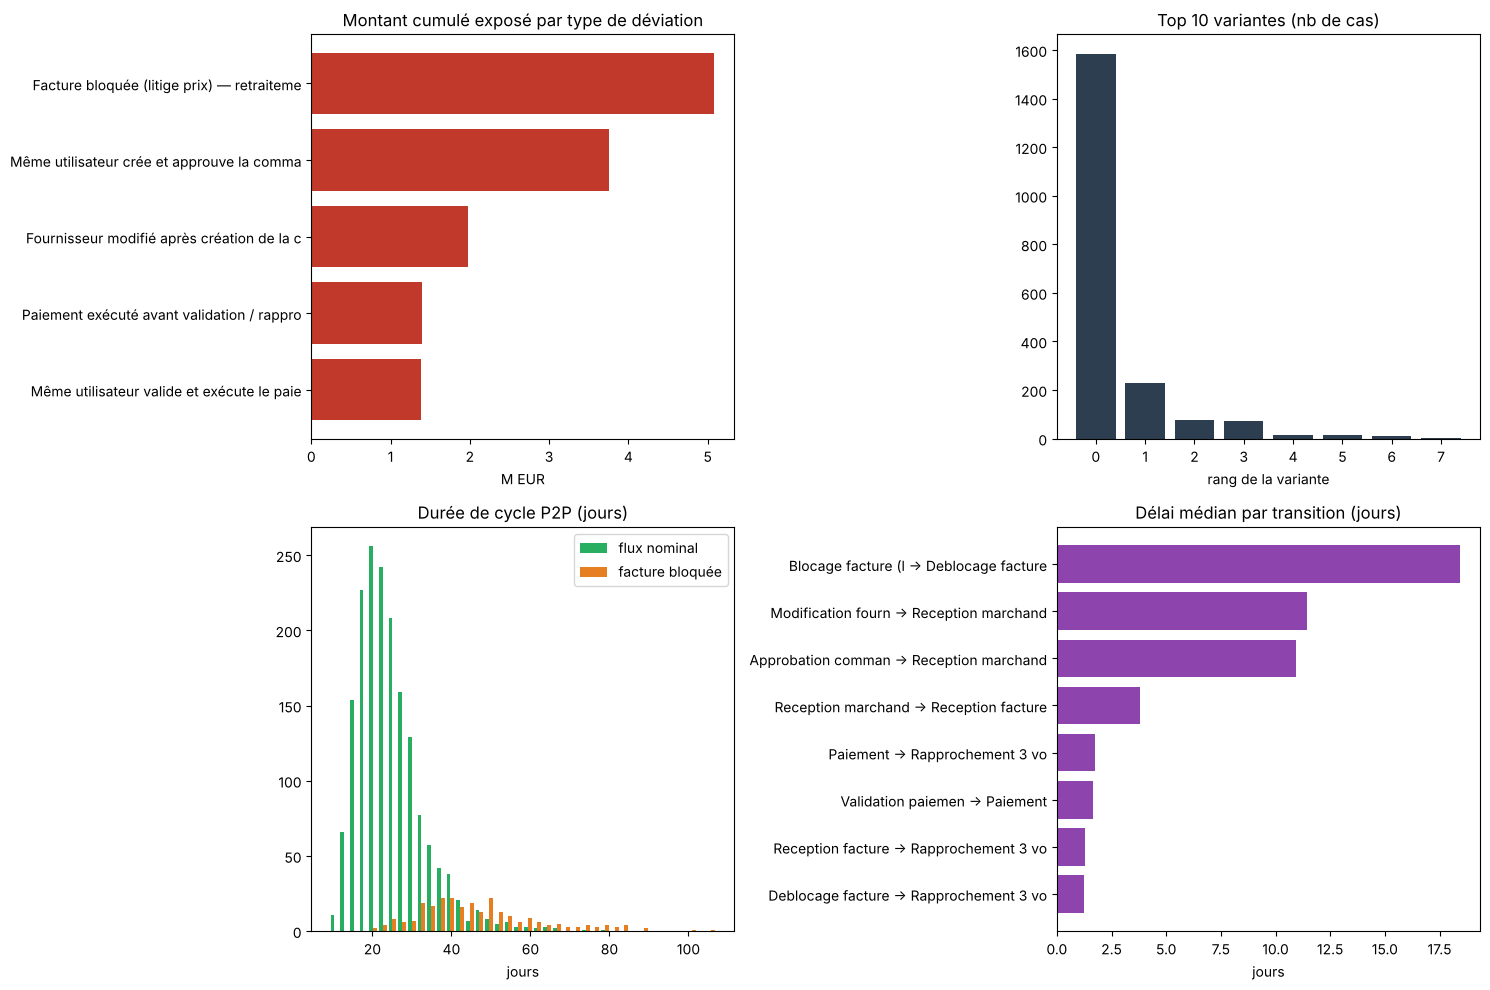

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
top = dev.sort_values("montant_cumule")
ax[0,0].barh([t[:42] for t in top.deviation], top.montant_cumule/1e6, color="#c0392b")
ax[0,0].set_title("Montant cumulé exposé par type de déviation"); ax[0,0].set_xlabel("M EUR")
ax[0,1].bar(range(len(vd[:10])), [n for n, _ in vd[:10]], color="#2c3e50")
ax[0,1].set_title("Top 10 variantes (nb de cas)"); ax[0,1].set_xlabel("rang de la variante")
ax[1,0].hist([cyc.loc[~cyc.bloquee, "cycle_j"], cyc.loc[cyc.bloquee, "cycle_j"]], bins=40,
             label=["flux nominal", "facture bloquée"], color=["#27ae60", "#e67e22"])
ax[1,0].set_title("Durée de cycle P2P (jours)"); ax[1,0].legend(); ax[1,0].set_xlabel("jours")
t8 = tr.head(8).iloc[::-1]
ax[1,1].barh([f"{a[:18]} → {b[:18]}" for a, b in zip(t8.activity, t8.next_act)], t8.mediane_j, color="#8e44ad")
ax[1,1].set_title("Délai médian par transition (jours)"); ax[1,1].set_xlabel("jours")
plt.tight_layout(); plt.savefig("out/04_synthese_audit.png", dpi=110); plt.show()

### Sélection d'échantillon pour tests de détail

Livrable opérationnel : la liste des cas à tester, priorisée par montant. C'est ce qu'on remet à l'équipe terrain.

In [14]:
ech = d[touche].copy()
ech["deviations"] = ech[list(LIB)].apply(lambda r: " | ".join(LIB[c][:35] for c in LIB if r[c]), axis=1)
ech = ech[["montant", "deviations"]].sort_values("montant", ascending=False)
ech.to_csv("out/echantillon_tests_detail.csv")
print(f"{len(ech)} cas à tester — top 15 par montant :")
ech.head(15)

618 cas à tester — top 15 par montant :


,montant,deviations
case_id,,
PO-00447,480000.00,Facture bloquée (litige prix) — ret
PO-01672,282041.89,Même utilisateur valide et exécute
PO-00206,237297.14,Même utilisateur crée et approuve l
PO-01270,205578.13,Même utilisateur crée et approuve l | Facture ...
PO-00074,203279.51,Même utilisateur crée et approuve l
PO-01362,163532.11,Facture bloquée (litige prix) — ret
PO-00819,125807.84,Fournisseur modifié après création
PO-01487,113317.97,Fournisseur modifié après création
PO-01036,112694.46,Fournisseur modifié après création


## 5. Note de synthèse d'audit

---

### Revue du cycle Achats–Fournisseurs (Purchase-to-Pay)
**Approche :** analyse exhaustive par process mining de l'intégralité des commandes de l'exercice (2 000 commandes, 18 618 événements, 35,3 M EUR d'engagements), par confrontation des traces du SI au processus cible documenté. La couverture est de 100 % de la population — elle ne repose pas sur un échantillon.

#### Constat n°1 — Contournement du contrôle de rapprochement à trois voies
**95 commandes (4,8 %), représentant 1,40 M EUR, ont donné lieu à un décaissement avant l'exécution du rapprochement à trois voies et avant la validation du paiement.** Le contrôle clé du cycle est donc exécuté *a posteriori*, à une médiane de 1,7 jour après le paiement, ce qui le prive de tout effet préventif : à ce stade, les fonds sont sortis et un écart de facturation ne peut plus donner lieu qu'à un recouvrement.

*Risque :* paiement de factures non justifiées, sur-facturation fournisseur non détectée, paiement en double.
*Recommandation :* bloquer techniquement l'exécution du paiement en l'absence de statut « rapproché » dans l'ERP, plutôt que de s'appuyer sur un contrôle procédural. Tester les 95 cas en détail sur l'exercice.

#### Constat n°2 — Défaillance de la séparation des tâches sur l'engagement de dépense
**208 commandes (10,4 %), pour 3,75 M EUR, ont été créées et approuvées par le même utilisateur.** S'y ajoutent 76 cas (1,39 M EUR) où la validation et l'exécution du paiement relèvent du même opérateur. Ces situations concernent principalement les commandes de montant unitaire modéré, ce qui suggère un seuil d'approbation contourné ou une matrice de délégation mal paramétrée plutôt que des incidents isolés.

*Risque :* engagement de dépense sans contrôle indépendant — exposition directe à la fraude interne et au détournement.
*Recommandation :* revue de la matrice des rôles et des règles de délégation dans l'ERP ; interdiction technique de l'auto-approbation, quel que soit le montant.

#### Constat n°3 — Modification de données fournisseur postérieure à l'engagement
**102 commandes (5,1 %), pour 1,97 M EUR, présentent une modification du fournisseur intervenue après l'approbation de la commande.** Le paiement a donc été exécuté au bénéfice d'un tiers différent de celui approuvé, sans nouveau cycle de validation.

*Risque :* schéma classique de fraude au changement de coordonnées bancaires.
*Recommandation :* toute modification des données fournisseur postérieure à l'approbation doit déclencher une réapprobation obligatoire et une notification au valideur initial. Vérifier l'existence et l'exhaustivité de la piste d'audit sur la table fournisseurs.

#### Constat n°4 — Goulot opérationnel sur le traitement des litiges de facturation
**258 commandes (12,9 %), pour 5,08 M EUR, ont subi un blocage facture pour litige de prix.** Le délai médian de déblocage est de **18,4 jours**, portant la durée de cycle médiane de 22,8 à **43,6 jours — soit +20,8 jours, un cycle deux fois plus long**. Cumulé, cela représente environ **5 360 jours-fournisseur de retard de paiement** sur l'exercice.

*Risque :* pénalités de retard, perte d'escomptes de règlement, dégradation de la relation fournisseur et risque de rupture d'approvisionnement. Le traitement manuel de ces litiges constitue par ailleurs une zone de contrôle affaiblie.
*Recommandation :* analyser les causes racines des écarts de prix (paramétrage des tolérances, actualisation des tarifs contractuels) et instaurer un seuil de tolérance automatique sur les écarts de faible montant.

#### Appréciation d'ensemble
**618 commandes, soit 30,9 % de la population et 11,73 M EUR (33,2 % des engagements), présentent au moins une déviation par rapport au processus cible.** Le taux de conformité intégrale s'établit à 79,2 %. Les constats n°1 à 3 relèvent de la conception et du paramétrage des contrôles applicatifs, et non de leur exécution : ils appellent une remédiation dans l'ERP plutôt qu'un renforcement des instructions de contrôle.

---

## 6. Points de méthode et limites

**Sur la méthode**
- Le process mining travaille sur la **population exhaustive**, pas sur un échantillon : on passe d'une assurance statistique à une assurance par couverture totale. C'est l'argument commercial central.
- **Alignments vs token-based replay** : les alignments sont plus coûteux mais donnent l'écart optimal et explicable, ce qui est indispensable quand un constat doit être opposable au client.
- **Inductive miner** : garantit un modèle *sound*, gère le bruit — à préférer à l'alpha miner, qui casse sur les boucles et le bruit.
- Le `noise_threshold` est un **choix de jugement professionnel** : trop bas, on reproduit le spaghetti ; trop haut, on masque les chemins d'exception, c'est-à-dire précisément ce qu'on cherche.

**Sur le rôle de l'auditeur**
- Une déviation détectée n'est pas un constat. Il faut la **qualifier** (faux positifs — cf. règle D4), la **chiffrer** en montant exposé, et la **rattacher à un risque** et à un contrôle défaillant.
- Toujours chiffrer en **euros et en nombre de cas**, jamais en fitness. Un taux de 0,979 ne parle à personne ; « 1,4 M EUR payés hors contrôle » parle à tout le monde.
- Distinguer **défaut de conception** (le contrôle n'existe pas ou peut être contourné techniquement) et **défaut d'exécution** (le contrôle existe mais n'est pas appliqué). La recommandation diffère radicalement.

**Limites**
- Qualité de l'extraction : si l'horodatage ERP est un *batch* nocturne, l'ordonnancement des activités devient faux et toute la détection d'antériorité s'effondre. **C'est le premier point à vérifier sur une mission réelle.**
- Les activités automatisées portent souvent un `user` technique (compte de service), ce qui fausse l'analyse de séparation des tâches — il faut les identifier et les exclure.
- Le process mining détecte des **anomalies de processus**, pas des fraudes : le constat ouvre un test de détail, il ne le remplace pas.
- Licence : PM4Py community est en AGPL v3. Les alternatives commerciales du marché sont Celonis, Signavio (SAP) et UiPath Process Mining.